# Nominatim vs Photon: how far off is each geocoder?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/Geocoding/blob/main/Notebook/02_Geocoding_With_Apis.ipynb)

Two free geocoders, both built on OpenStreetMap and both reachable from `geopy` without an API key:
- **[Nominatim](https://nominatim.org/)** (OSM Foundation): structured search, strict usage policy.
- **[Photon](https://photon.komoot.io/)** (komoot): search-as-you-type, more forgiving with partial names.

I geocode the same 10 Tokyo landmarks with both and measure the **error in metres** against the coordinates in [Wikidata](https://www.wikidata.org/) (property P625), fixed below with their QIDs so the comparison is reproducible.

Both services are queried at **1 request per second** with a User-Agent of their own, and the answers are cached on disk.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim, Photon
from geopy.extra.rate_limiter import RateLimiter

In [2]:
USER_AGENT = "oechenique-geocoding-tutorial/1.0 (+https://github.com/oechenique/Geocoding)"

providers = {
    "Nominatim": RateLimiter(Nominatim(user_agent=USER_AGENT, timeout=10).geocode, min_delay_seconds=1, max_retries=2),
    "Photon": RateLimiter(Photon(user_agent=USER_AGENT, timeout=10).geocode, min_delay_seconds=1, max_retries=2),
}

In [3]:
import json
from pathlib import Path

CACHE = Path("cache/geocoding.json")  # out of git: re-running the notebook does not hit the APIs again


def cached(key, fn):
    """Return fn() from a JSON cache on disk. Only JSON-serializable results go in."""
    store = json.loads(CACHE.read_text(encoding="utf-8")) if CACHE.exists() else {}
    if key not in store:
        store[key] = fn()
        CACHE.parent.mkdir(exist_ok=True)
        CACHE.write_text(json.dumps(store, ensure_ascii=False, indent=1), encoding="utf-8")
    return store[key]

## 1. Reference: 10 landmarks with Wikidata coordinates

Coordinates taken from Wikidata on 2026-10-30. Wikidata places a single point per item, usually the centre of the building; it is a reference, not ground truth (a shrine with a large forest, like Meiji Jingū, has no single "right" point).

In [4]:
landmarks = pd.DataFrame([
    ("Tokyo Tower", "Q183536", 35.658611, 139.745556),
    ("Tokyo Skytree", "Q57965", 35.710056, 139.810722),
    ("Sensō-ji", "Q615183", 35.714556, 139.796639),
    ("Meiji Jingū", "Q287165", 35.676111, 139.699167),
    ("Tokyo Station", "Q283196", 35.680833, 139.766944),
    ("Shibuya Scramble Crossing", "Q21083961", 35.659503, 139.700544),
    ("Tokyo Metropolitan Government Building", "Q111973", 35.689510, 139.691710),
    ("Nakano Broadway", "Q10856007", 35.709167, 139.665556),
    ("Tsukiji Hongan-ji", "Q943255", 35.666389, 139.772222),
    ("Kabuki-za", "Q3082575", 35.669722, 139.768056),
], columns=["name", "wikidata", "ref_lat", "ref_lon"])
landmarks

,name,wikidata,ref_lat,ref_lon
0,Tokyo Tower,Q183536,35.658611,139.745556
1,Tokyo Skytree,Q57965,35.710056,139.810722
2,Sensō-ji,Q615183,35.714556,139.796639
3,Meiji Jingū,Q287165,35.676111,139.699167
4,Tokyo Station,Q283196,35.680833,139.766944
5,Shibuya Scramble Crossing,Q21083961,35.659503,139.700544
6,Tokyo Metropolitan Government Building,Q111973,35.689510,139.691710
7,Nakano Broadway,Q10856007,35.709167,139.665556
8,Tsukiji Hongan-ji,Q943255,35.666389,139.772222
9,Kabuki-za,Q3082575,35.669722,139.768056


## 2. Geocode with both providers

The same query for both: `"<name>, Tokyo"`. 10 landmarks × 2 providers = 20 requests, about 20 s on the first run and none afterwards (cache).

In [5]:
def run(provider, query):
    loc = providers[provider](query)
    return None if loc is None else {"lat": loc.latitude, "lon": loc.longitude, "address": loc.address}


rows = []
for lm in landmarks.itertuples():
    for provider in providers:
        query = f"{lm.name}, Tokyo"
        hit = cached(f"{provider}|{query}", lambda p=provider, q=query: run(p, q))
        rows.append({"name": lm.name, "provider": provider, "found": hit is not None,
                     "lat": hit and hit["lat"], "lon": hit and hit["lon"], "address": hit and hit["address"]})
results = pd.DataFrame(rows).merge(landmarks, on="name")
results[["name", "provider", "found", "address"]]

,name,provider,found,address
0,Tokyo Tower,Nominatim,True,"東京タワー, タクシー乗り場, 芝公園四丁目, 芝公園, 港区, 東京都, 105-0011..."
1,Tokyo Tower,Photon,True,"東京タワー, 東京タワー通り, 106-0041, 東京タワー通り, 東京都, 日本"
2,Tokyo Skytree,Nominatim,True,"東京スカイツリー, 2, 押上一丁目, 押上, 墨田区, 東京都, 131-0045, 日本"
3,Tokyo Skytree,Photon,True,"東京スカイツリー, 2, 1, 131-0045, 1, 墨田区, 東京都, 日本"
4,Sensō-ji,Nominatim,True,"Храм Сенсодзи 金龍山 浅草寺, 1, 浅草二丁目, 浅草, 台東区, 東京都,..."
5,Sensō-ji,Photon,True,"Храм Сенсодзи 金龍山 浅草寺, 1, 3, 111-0032, 3, 台東区, 日本"
6,Meiji Jingū,Nominatim,True,"明治神宮, 1, 代々木神園町, 渋谷区, 東京都, 151-8557, 日本"
7,Meiji Jingū,Photon,True,"明治神宮野球場, 1, 3, 160-0013, 3, 新宿区, 東京都, 日本"
8,Tokyo Station,Nominatim,True,"東京駅(改札外), 丸の内一丁目, 丸の内, 千代田区, 東京都, 100-0005, 日本"
9,Tokyo Station,Photon,True,"東京テレポート駅前, テレポートブリッジ, 135-0091, テレポートブリッジ, 東京都..."


## 3. Error in metres

Distances are computed in **UTM zone 54N (EPSG:32654)**, a metric CRS for Tokyo; measuring in degrees would mix up north–south and east–west distances.

In [6]:
found = results[results["found"]].copy()
got = gpd.GeoSeries(gpd.points_from_xy(found["lon"], found["lat"]), crs="EPSG:4326").to_crs(32654)
ref = gpd.GeoSeries(gpd.points_from_xy(found["ref_lon"], found["ref_lat"]), crs="EPSG:4326").to_crs(32654)
found["error_m"] = got.distance(ref).round(0).values

errors = found.pivot(index="name", columns="provider", values="error_m").reindex(landmarks["name"])
errors

provider,Nominatim,Photon
name,,
Tokyo Tower,18.0,18.0
Tokyo Skytree,1.0,1.0
Sensō-ji,163.0,163.0
Meiji Jingū,147.0,1643.0
Tokyo Station,225.0,6045.0
Shibuya Scramble Crossing,4.0,4.0
Tokyo Metropolitan Government Building,NaN,2.0
Nakano Broadway,14.0,14.0
Tsukiji Hongan-ji,25.0,25.0


In [7]:
summary = pd.DataFrame({
    "found (of 10)": results.groupby("provider")["found"].sum(),
    "median error (m)": found.groupby("provider")["error_m"].median(),
    "max error (m)": found.groupby("provider")["error_m"].max(),
    "within 100 m": found.assign(ok=found["error_m"] <= 100).groupby("provider")["ok"].sum(),
})
summary

,found (of 10),median error (m),max error (m),within 100 m
provider,,,,
Nominatim,9,18.0,225.0,6
Photon,10,21.5,6758.0,6


## 4. Figure

Error per landmark, log scale: a wrong match is kilometres off while a good one is tens of metres. (For the points on a map, `results` can go straight into `GeoDataFrame.explore()`.)

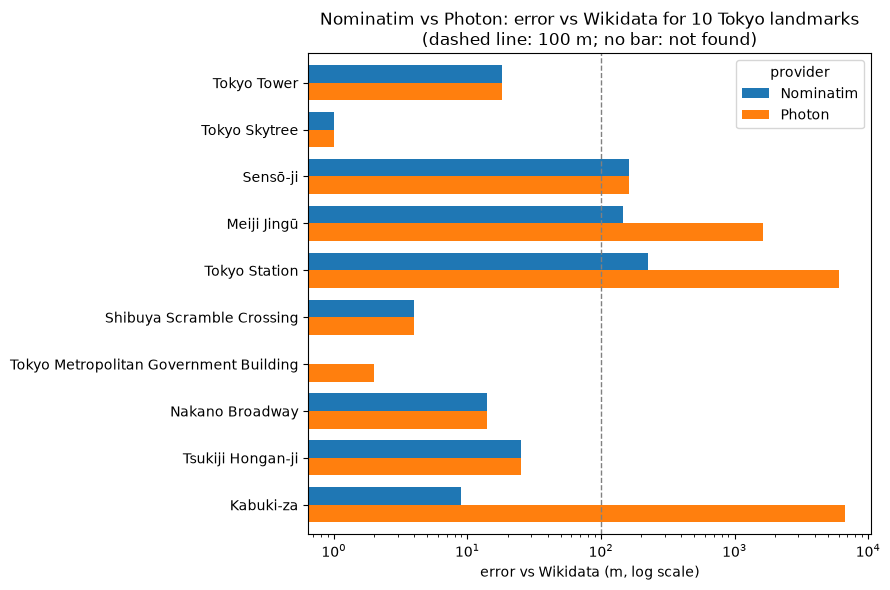

In [8]:
colors = {"Nominatim": "#1f77b4", "Photon": "#ff7f0e"}

fig, ax_bar = plt.subplots(figsize=(9, 6))
errors.plot.barh(ax=ax_bar, color=colors, logx=True, width=0.75)
ax_bar.axvline(100, color="grey", ls="--", lw=1)
ax_bar.invert_yaxis()
ax_bar.set_xlabel("error vs Wikidata (m, log scale)")
ax_bar.set_ylabel("")
ax_bar.set_title("Nominatim vs Photon: error vs Wikidata for 10 Tokyo landmarks\n(dashed line: 100 m; no bar: not found)")
fig.tight_layout()

if Path("../docs/img").exists():  # README figure, only when run from a clone of the repo
    fig.savefig("../docs/img/nominatim_vs_photon.png", dpi=110, bbox_inches="tight")
plt.show()

## Takeaways

- **Nominatim** found 9 of 10 (it missed the Tokyo Metropolitan Government Building), median error **18 m**, worst **225 m** (Tokyo Station, a huge building).
- **Photon** found all 10, median **21.5 m**, but 3 of them are **a different place**: Meiji Jingū → the Meiji Jingū baseball stadium (1.6 km), Tokyo Station → Tokyo Teleport station (6.0 km), Kabuki-za → Theater Milano-Za in Shinjuku (6.8 km). Its fuzzy, search-as-you-type matching finds more and is wrong more.
- Both are within 100 m for 6 of 10. These numbers describe **these 10 queries**, not the services in general: they depend on how each landmark is mapped in OSM.
- A geocoder can return *something* and still be wrong; without a reference (or at least a distance or bounding-box check) you would not notice.
- On the public servers, keep it to a handful of requests: both ask for fair use. For thousands of addresses, run your own Nominatim/Photon instance or use a paid API.

Data © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), ODbL · reference coordinates from [Wikidata](https://www.wikidata.org/), CC0.